# Smart Parking Space Management — 3-State MDP

**Colab-ready implementation** following the uploaded `GYM_MDP.ipynb` approach: create a Gymnasium environment, inspect its `P` transition dictionary, and run a simulation.

- **States:** S1 Parking Available, S2 Parking Nearly Full, S3 Parking Full
- **Actions:** A1 Admit Vehicle, A2 Redirect Vehicle
- **No discounting:** $\gamma=1$
- **Finite horizon:** 8 decisions per episode, to keep undiscounted returns finite.

**Modeling assumption:** This is the same *simplified deterministic* transition table as the README, not a physical occupancy simulator. In particular, a redirect does not itself free a space; the transitions S2→S1 and S3→S2 implicitly assume departures during the decision interval.

In [1]:
!pip -q install gymnasium networkx matplotlib

## 1. Define the MDP (same transition and reward tables as README)

In [2]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np

print("Name: S Lalit Chandran")
print("Register Number: __________")

states = {0: "S1: Parking Available", 1: "S2: Parking Nearly Full", 2: "S3: Parking Full"}
actions = {0: "A1: Admit Vehicle", 1: "A2: Redirect Vehicle"}
gamma = 1.0
HORIZON = 8

# (state, action): (next_state, immediate_reward)
model = {
    (0, 0): (1, 10),
    (0, 1): (0, 2),
    (1, 0): (2, 5),
    (1, 1): (0, 8),
    (2, 0): (2, -10),
    (2, 1): (1, 10),
}

# Gym-style P: state -> action -> [(probability, next_state, reward, terminated)]
P = {s: {a: [(1.0, *model[(s, a)], False)] for a in actions} for s in states}
print("Discount factor (no discounting):", gamma)
print("State space:", states)
print("Action space:", actions)
print("\nTransition model P:")
for s in P:
    for a, outcomes in P[s].items():
        print(f"{states[s]} | {actions[a]} -> {outcomes}")

Name: S Lalit Chandran
Register Number: __________
Discount factor (no discounting): 1.0
State space: {0: 'S1: Parking Available', 1: 'S2: Parking Nearly Full', 2: 'S3: Parking Full'}
Action space: {0: 'A1: Admit Vehicle', 1: 'A2: Redirect Vehicle'}

Transition model P:
S1: Parking Available | A1: Admit Vehicle -> [(1.0, 1, 10, False)]
S1: Parking Available | A2: Redirect Vehicle -> [(1.0, 0, 2, False)]
S2: Parking Nearly Full | A1: Admit Vehicle -> [(1.0, 2, 5, False)]
S2: Parking Nearly Full | A2: Redirect Vehicle -> [(1.0, 0, 8, False)]
S3: Parking Full | A1: Admit Vehicle -> [(1.0, 2, -10, False)]
S3: Parking Full | A2: Redirect Vehicle -> [(1.0, 1, 10, False)]


## 2. Build a Gymnasium environment

In [3]:
class SmartParkingEnv(gym.Env):
    metadata = {"render_modes": ["ansi"]}

    def __init__(self, horizon=8):
        super().__init__()
        self.observation_space = spaces.Discrete(3)
        self.action_space = spaces.Discrete(2)
        self.P = P
        self.horizon = horizon
        self.state = 0
        self.steps = 0

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        self.state = 0  # always begin with parking available
        self.steps = 0
        return self.state, {}

    def step(self, action):
        if not self.action_space.contains(action):
            raise ValueError(f"Invalid action: {action}")
        probability, next_state, reward, terminated = self.P[self.state][int(action)][0]
        self.state = next_state
        self.steps += 1
        truncated = self.steps >= self.horizon
        return next_state, float(reward), terminated, truncated, {"probability": probability}

    def render(self):
        return states[self.state]

env = SmartParkingEnv(horizon=HORIZON)
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)
print("Initial state:", states[env.reset()[0]])
print("\nenv.P:", env.P)

Observation space: Discrete(3)
Action space: Discrete(2)
Initial state: S1: Parking Available

env.P: {0: {0: [(1.0, 1, 10, False)], 1: [(1.0, 0, 2, False)]}, 1: {0: [(1.0, 2, 5, False)], 1: [(1.0, 0, 8, False)]}, 2: {0: [(1.0, 2, -10, False)], 1: [(1.0, 1, 10, False)]}}


## 3. Transition probability and reward table

In [4]:
print(f"{'Current State':<26} {'Action':<23} {'Next State':<26} {'P':>4} {'Reward':>7}")
print('-' * 92)
for s in states:
    for a in actions:
        for probability, next_state, reward, terminated in env.P[s][a]:
            print(f"{states[s]:<26} {actions[a]:<23} {states[next_state]:<26} {probability:>4.1f} {reward:>+7}")
        assert abs(sum(x[0] for x in env.P[s][a]) - 1.0) < 1e-9
print("\nAll transition probabilities sum to 1.")

Current State              Action                  Next State                    P  Reward
--------------------------------------------------------------------------------------------
S1: Parking Available      A1: Admit Vehicle       S2: Parking Nearly Full     1.0     +10
S1: Parking Available      A2: Redirect Vehicle    S1: Parking Available       1.0      +2
S2: Parking Nearly Full    A1: Admit Vehicle       S3: Parking Full            1.0      +5
S2: Parking Nearly Full    A2: Redirect Vehicle    S1: Parking Available       1.0      +8
S3: Parking Full           A1: Admit Vehicle       S3: Parking Full            1.0     -10
S3: Parking Full           A2: Redirect Vehicle    S2: Parking Nearly Full     1.0     +10

All transition probabilities sum to 1.


## 4. MDP graph — state, action, probability, reward

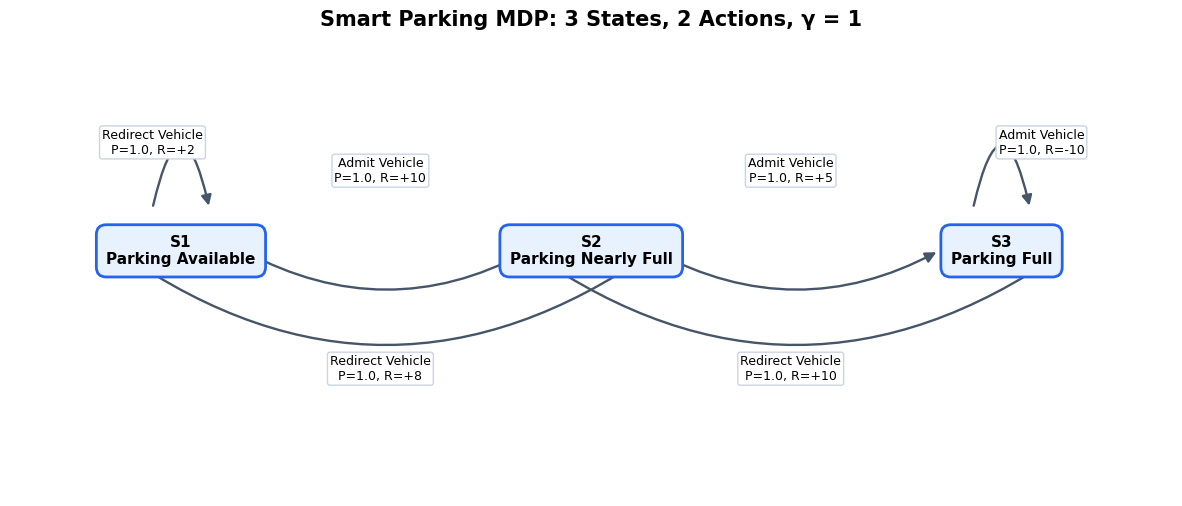

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

# Manual positions keep the 3-state diagram readable, including self-loops.
pos = {0: (0, 1), 1: (3.6, 1), 2: (7.2, 1)}
fig, ax = plt.subplots(figsize=(15, 6))
ax.set_xlim(-1.5, 8.7)
ax.set_ylim(-1.6, 3.3)
ax.axis('off')
for s, (x, y) in pos.items():
    ax.text(x, y, states[s].replace(': ', '\n'), ha='center', va='center',
            fontsize=11, fontweight='bold', bbox=dict(boxstyle='round,pad=0.65', fc='#e8f2ff', ec='#2563eb', lw=2))

# Draw curved arrows to distinguish multiple transitions between the same nodes.
edge_specs = {
    (0, 0): (0.27, (1.75, 1.85)),
    (0, 1): (0.0, (-0.25, 2.15)),
    (1, 0): (0.27, (5.35, 1.85)),
    (1, 1): (-0.35, (1.75, -0.25)),
    (2, 0): (0.0, (7.55, 2.15)),
    (2, 1): (-0.35, (5.35, -0.25)),
}
for (s, a), (curve, label_xy) in edge_specs.items():
    prob, t, reward, _ = env.P[s][a][0]
    x1, y1 = pos[s]; x2, y2 = pos[t]
    if s == t:
        # Self-loop rendered as a small curved path above the node.
        loop = FancyArrowPatch((x1-0.25, y1+0.45), (x1+0.25, y1+0.45),
                               connectionstyle='arc3,rad=-2.2', arrowstyle='-|>',
                               mutation_scale=15, linewidth=1.7, color='#475569')
        ax.add_patch(loop)
    else:
        arrow = FancyArrowPatch((x1+0.55, y1), (x2-0.55, y2),
                                connectionstyle=f'arc3,rad={curve}', arrowstyle='-|>',
                                mutation_scale=16, linewidth=1.7, color='#475569')
        ax.add_patch(arrow)
    ax.text(*label_xy, f"{actions[a].split(': ')[1]}\nP={prob:.1f}, R={reward:+d}",
            fontsize=9, ha='center', va='center',
            bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='#cbd5e1'))
ax.set_title('Smart Parking MDP: 3 States, 2 Actions, γ = 1', fontsize=15, fontweight='bold')
plt.show()

## 5. Simulate a finite episode (8 steps, no discounting)

In [6]:
# Simple illustrative rule, not a computed optimal policy.
policy = {0: 0, 1: 1, 2: 1}
obs, info = env.reset(seed=42)
total_reward = 0
print(f"{'Step':<5} {'State':<26} {'Action':<23} {'Next state':<26} {'Reward':>6}")
print('-' * 95)
for step in range(1, HORIZON + 1):
    action = policy[obs]
    next_obs, reward, terminated, truncated, info = env.step(action)
    print(f"{step:<5} {states[obs]:<26} {actions[action]:<23} {states[next_obs]:<26} {reward:>+6.0f}")
    total_reward += reward  # gamma=1: undiscounted sum
    obs = next_obs
    if terminated or truncated:
        break
print(f"\nTotal undiscounted reward: {total_reward:.0f}")
print("Episode ended:", 'time limit reached' if truncated else 'terminal state')

Step  State                      Action                  Next state                 Reward
-----------------------------------------------------------------------------------------------
1     S1: Parking Available      A1: Admit Vehicle       S2: Parking Nearly Full       +10
2     S2: Parking Nearly Full    A2: Redirect Vehicle    S1: Parking Available          +8
3     S1: Parking Available      A1: Admit Vehicle       S2: Parking Nearly Full       +10
4     S2: Parking Nearly Full    A2: Redirect Vehicle    S1: Parking Available          +8
5     S1: Parking Available      A1: Admit Vehicle       S2: Parking Nearly Full       +10
6     S2: Parking Nearly Full    A2: Redirect Vehicle    S1: Parking Available          +8
7     S1: Parking Available      A1: Admit Vehicle       S2: Parking Nearly Full       +10
8     S2: Parking Nearly Full    A2: Redirect Vehicle    S1: Parking Available          +8

Total undiscounted reward: 72
Episode ended: time limit reached


## 6. Optional: Find the optimal policy for the finite horizon

With $\gamma=1$, finite-horizon dynamic programming is well-defined. The best action may depend on how many decisions remain.

In [7]:
V = np.zeros((HORIZON + 1, len(states)))
best_action = np.zeros((HORIZON + 1, len(states)), dtype=int)
for remaining in range(1, HORIZON + 1):
    for s in states:
        q = []
        for a in actions:
            q.append(sum(p * (r + gamma * V[remaining - 1, ns])
                         for p, ns, r, done in env.P[s][a]))
        best_action[remaining, s] = int(np.argmax(q))
        V[remaining, s] = max(q)
print('Optimal first action with 8 decisions remaining:')
for s in states:
    a = best_action[HORIZON, s]
    print(f'{states[s]} -> {actions[a]} (expected total reward: {V[HORIZON, s]:.0f})')
print('\nNote: these are optimal actions for the simplified model and chosen reward table.')

Optimal first action with 8 decisions remaining:
S1: Parking Available -> A1: Admit Vehicle (expected total reward: 72)
S2: Parking Nearly Full -> A2: Redirect Vehicle (expected total reward: 72)
S3: Parking Full -> A2: Redirect Vehicle (expected total reward: 72)

Note: these are optimal actions for the simplified model and chosen reward table.
